# γp → K⁺Λ event generator: settings and diagnostics

This notebook runs `gen_khyperon` to produce γp → K⁺Λ, Λ → pπ⁻ events with
linearly polarized photons, then checks the generated events against the
model they were drawn from.

The generator uses only ROOT and AmpTools (no GlueX software):

1. **Beam:** photon energy flat in [`E_LOW`, `E_HIGH`] (or 1/E, or a flux histogram), along +z, with a constant linear polarization.
2. **Production:** −t thrown from `exp(-b_t|t|) + uFrac·exp(-b_u|u|)`, a forward t-channel peak plus an optional backward u-channel peak.
3. **Λ decay:** Λ → pπ⁻ with the polarization observables Σ, P, T, Ox, Oz applied through the `KHyperon` amplitude in AmpTools (the CLAS intensity, PRC 93, 065201).

All settings are in the **Settings** cell.  Change them there and rerun the notebook.

**Requirements:** ROOT with PyROOT, numpy, matplotlib and Jupyter.  The first
code cell builds the generator if needed (`make amptools && make` in
`standalone/`, which needs git, make and a C++17 compiler).  See
`standalone/README.md` for details.

In [1]:
import os
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import ROOT

ROOT.gROOT.SetBatch(True)

# The notebook lives in analysis/kplamb/fitting; set FITDIR by hand if you run it elsewhere.
FITDIR = Path.cwd()
STANDALONE = FITDIR / "standalone"
GEN = STANDALONE / "gen_khyperon"
OUTDIR = FITDIR / "gen_khyperon_output"

if not STANDALONE.is_dir():
    raise RuntimeError(f"{STANDALONE} not found: set FITDIR to analysis/kplamb/fitting")

# build the generator on first use
if not GEN.exists():
    if not (STANDALONE / "AmpTools").exists() and "AMPTOOLS" not in os.environ:
        subprocess.run(["make", "amptools"], cwd=STANDALONE, check=True)
    subprocess.run(["make", "-j4"], cwd=STANDALONE, check=True)

OUTDIR.mkdir(exist_ok=True)
print("generator:", GEN.relative_to(FITDIR))
print("output:   ", OUTDIR.relative_to(FITDIR))

generator: standalone/gen_khyperon
output:    gen_khyperon_output


## Settings

| Setting | Meaning |
| --- | --- |
| `E_LOW`, `E_HIGH`, `BEAM` | photon energy range in GeV and spectrum shape (`flat` or `brem` for 1/E) |
| `T_MIN`, `T_MAX` | −t window in GeV² for the polarized sample (the polarization analysis uses 0.1–2.1) |
| `T_SLOPE`, `U_SLOPE` | slopes b_t and b_u in GeV⁻² |
| `U_FRAC` | backward peak height at u = 0 relative to the forward peak at t = 0 (0 turns it off) |
| `POL_ANGLE`, `POL_FRACTION` | beam polarization plane in degrees from the lab x axis, and degree of polarization |
| `ALPHA` | Λ → pπ⁻ decay asymmetry parameter |
| `OBSERVABLES` | Σ, Ox, P, T, Oz used for the polarized sample, held constant over t and E |

The default slopes (b_t ≈ 4.7, b_u ≈ 5.3, R ≈ 0.006) correspond to K\*(892)
and Λ Regge trajectories at E_γ ≈ 8.5 GeV.  They are reasonable starting
values, not fits to data.

In [2]:
# ---- event counts and random seed ----
N_POLARIZED = 200_000      # polarized sample in the analysis -t window
N_PRODUCTION = 1_000_000   # unpolarized sample over the full angular range
SEED = 1

# ---- beam ----
E_LOW, E_HIGH = 8.2, 8.8   # GeV
BEAM = "flat"              # "flat" or "brem" (1/E)

# ---- production model: exp(-b_t|t|) + U_FRAC * exp(-b_u|u|) ----
T_MIN, T_MAX = 0.1, 2.1    # GeV^2, window for the polarized sample
T_SLOPE = 4.7              # GeV^-2
U_SLOPE = 5.3              # GeV^-2
U_FRAC = 0.006

# ---- beam polarization and Lambda decay ----
POL_ANGLE = 1.77           # degrees (PARA 0 orientation)
POL_FRACTION = 0.35
ALPHA = 0.732
OBSERVABLES = dict(Sigma=0.40, Ox=-0.30, P=-0.20, T=0.50, Oz=0.20)

TREE = "ntFSGlueX_100000000_100000"

## Generate the samples

Two samples are generated:

- **`polarized.root`**: the physics sample.  It uses the production model in the −t window above, then accepts or rejects each event on the `KHyperon` intensity.
- **`production_full.root`**: the same production model over the whole angular range (`-tmax 20`), with flat Λ decay (`-f`).  It is used to check the t, u and cos θ_CM distributions, including the backward peak.

The generation config for the polarized sample is written from the settings
above, with the same syntax as the fit configs in this directory.

In [3]:
cfg_text = f'''# written by gen_khyperon_diagnostics.ipynb
fit khyperon_gen
reaction khyperon Beam K+ Proton Pi-
parameter polAngle {POL_ANGLE} fixed
sum khyperon khyperonPol
amplitude khyperon::khyperonPol::khyperonAmp KHyperon [alpha] [Sigma] [Ox] [P] [T] [Oz] [polAngle] {POL_FRACTION}
parameter alpha {ALPHA} fixed
''' + "".join(f"parameter {k} {v} fixed\n" for k, v in OBSERVABLES.items()) + '''initialize khyperon::khyperonPol::khyperonAmp cartesian 1.0 0.0 real
'''
CFG = OUTDIR / "gen_polarized.cfg"
CFG.write_text(cfg_text)

common = ["-a", E_LOW, "-b", E_HIGH, "-beam", BEAM, "-t", T_SLOPE, "-u", U_SLOPE, "-uFrac", U_FRAC]


def run_gen(args):
    # runs inside OUTDIR, so file names are relative to it
    cmd = [str(GEN)] + [str(a) for a in args]
    print("$ gen_khyperon " + " ".join(cmd[1:]))
    result = subprocess.run(cmd, capture_output=True, text=True, cwd=OUTDIR)
    if result.returncode != 0:
        print(result.stdout[-3000:], result.stderr[-3000:])
        raise RuntimeError("gen_khyperon failed")
    keys = ("Production model", "efficiency", "Wrote", "WARNING")
    lines = [l.strip() for l in result.stdout.splitlines() if any(k in l for k in keys)]
    accepted = [l.strip() for l in result.stdout.splitlines() if "events accepted" in l]
    print("  " + "\n  ".join(lines + accepted[-1:]))


run_gen(["-c", CFG.name, "-o", "polarized.root", "-n", N_POLARIZED, "-s", SEED,
         "-tmin", T_MIN, "-tmax", T_MAX, "-tree", TREE] + common)
run_gen(["-f", "-o", "production_full.root", "-n", N_PRODUCTION, "-s", SEED + 1,
         "-tmin", 0, "-tmax", 20, "-tree", TREE] + common)

$ gen_khyperon -c gen_polarized.cfg -o polarized.root -n 200000 -s 1 -tmin 0.1 -tmax 2.1 -tree ntFSGlueX_100000000_100000 -a 8.2 -b 8.8 -beam flat -t 4.7 -u 5.3 -uFrac 0.006


  Production model: exp(-4.7 |t|) + 0.006 exp(-5.3 |u|),  0.1 < -t < 2.1 GeV^2
  accept/reject efficiency: 0.70281
  200000 / 200000 events accepted
$ gen_khyperon -f -o production_full.root -n 1000000 -s 2 -tmin 0 -tmax 20 -tree ntFSGlueX_100000000_100000 -a 8.2 -b 8.8 -beam flat -t 4.7 -u 5.3 -uFrac 0.006


  Production model: exp(-4.7 |t|) + 0.006 exp(-5.3 |u|),  0 < -t < 20 GeV^2
  Wrote 1000000 events


## Kinematics from the four-vectors

All quantities are computed here from the four-vectors in the output tree, not
taken from the generator, so the checks below are independent of the
generator code.  The Λ decay frame matches the `KHyperon` amplitude used in
the fit:

- ŷ is normal to the production plane (beam × −K⁺).
- ẑ points opposite the K⁺ in the Λ rest frame.
- x̂ = ŷ × ẑ.
- cos θ_x, cos θ_y and cos θ_z are the proton direction in the Λ rest frame projected on those axes.
- Φ is the angle between the production plane and the lab x axis.

In [4]:
M_P, M_K, M_L = 0.938272, 0.493677, 1.115683
SUM_M2 = M_P**2 + M_K**2 + M_L**2
LABELS = {"B": "beam", "2": "K+", "1a": "p", "1b": "pi-"}


def load(path):
    cols = [f"MC{c}P{l}" for l in LABELS for c in ("En", "Px", "Py", "Pz")]
    arrays = ROOT.RDataFrame(TREE, str(path)).AsNumpy(cols)
    return {name: np.stack([arrays[f"MC{c}P{l}"] for c in ("En", "Px", "Py", "Pz")], axis=1)
            for l, name in LABELS.items()}


def mass2(p4):
    return p4[:, 0]**2 - np.sum(p4[:, 1:]**2, axis=1)


def unit(v):
    return v / np.linalg.norm(v, axis=1, keepdims=True)


def boost(p4, beta):
    # Lorentz boost of four-vectors p4 = (E, px, py, pz) by velocity beta
    b2 = np.sum(beta**2, axis=1)
    gamma = 1.0 / np.sqrt(1.0 - b2)
    bp = np.sum(beta * p4[:, 1:], axis=1)
    g2 = np.where(b2 > 0, (gamma - 1.0) / np.where(b2 > 0, b2, 1.0), 0.0)
    vec = p4[:, 1:] + (g2 * bp + gamma * p4[:, 0])[:, None] * beta
    return np.column_stack([gamma * (p4[:, 0] + bp), vec])


def kinematics(ev):
    beam, k, p, pi = ev["beam"], ev["K+"], ev["p"], ev["pi-"]
    lam = p + pi
    target = np.tile([M_P, 0.0, 0.0, 0.0], (len(beam), 1))
    cm = beam + target
    k_cm = boost(k, -cm[:, 1:] / cm[:, [0]])

    beam_hat = unit(beam[:, 1:])
    lam_beta = lam[:, 1:] / lam[:, [0]]
    k_lam = boost(k, -lam_beta)
    p_lam = boost(p, -lam_beta)
    y = unit(np.cross(beam_hat, -unit(k[:, 1:])))
    z = -unit(k_lam[:, 1:])
    x = unit(np.cross(y, z))
    p_hat = unit(p_lam[:, 1:])
    eps = np.array([1.0, 0.0, 0.0])

    return dict(
        E=beam[:, 0],
        t=-mass2(target - lam),
        u=-mass2(beam - lam),
        cos_cm=np.sum(unit(k_cm[:, 1:]) * beam_hat, axis=1),
        m_lambda=np.sqrt(mass2(lam)),
        cx=np.sum(p_hat * x, axis=1),
        cy=np.sum(p_hat * y, axis=1),
        cz=np.sum(p_hat * z, axis=1),
        Phi=np.arctan2(y @ eps, np.sum(beam_hat * np.cross(eps, y), axis=1)),
    )


pol_ev = load(OUTDIR / "polarized.root")
full_ev = load(OUTDIR / "production_full.root")
pol = kinematics(pol_ev)
full = kinematics(full_ev)
print(f"polarized sample: {len(pol['t']):,} events,  production sample: {len(full['t']):,} events")
print(f"M(p pi-) = {pol['m_lambda'].mean():.6f} GeV (fixed Lambda mass, no width)")

polarized sample: 200,000 events,  production sample: 1,000,000 events
M(p pi-) = 1.115683 GeV (fixed Lambda mass, no width)


## Expected distributions

The model curves come from numerically integrating the production model over
a fine grid in beam energy and K⁺ CM angle, using the same −t window as the
generator.  They are independent of the generator's random sampling.

In [5]:
BLUE, ORANGE = "#2a78d6", "#eb6834"        # generated, model
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": INK2, "axes.linewidth": 0.8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "grid.linestyle": "-", "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "font.size": 10,
})


def breakup(M, m1, m2):
    return np.sqrt((M**2 - (m1 + m2)**2) * (M**2 - (m1 - m2)**2)) / (2 * M)


def model_hist(var, bins, t_lo, t_hi, n_events, nE=81, nC=40001):
    # expected counts per bin for var in {"t", "u", "cos_cm", "E"}
    E = np.linspace(E_LOW, E_HIGH, nE + 1)
    E = 0.5 * (E[1:] + E[:-1])[:, None]
    s = M_P**2 + 2 * M_P * E
    W = np.sqrt(s)
    pg, pk = breakup(W, 0.0, M_P), breakup(W, M_K, M_L)
    ek = np.sqrt(pk**2 + M_K**2)
    c = np.linspace(-1, 1, nC)[None, :]
    t = M_K**2 - 2 * (pg * ek - pg * pk * c)
    u = SUM_M2 - s - t
    flux = 1.0 / E if BEAM == "brem" else np.ones_like(E)
    w = flux * (np.exp(T_SLOPE * t) + U_FRAC * np.exp(U_SLOPE * u))   # t, u < 0
    w = w * 2 * pg * pk * ((-t >= t_lo) & (-t <= t_hi))   # dt = 2 pg pk dcos
    if var == "E":
        # integrate the smooth per-energy rate over each bin (a direct histogram
        # of the coarse energy grid would alias against the bins)
        rate = w.sum(axis=1) / w.sum() / (E[1, 0] - E[0, 0])
        fine = np.linspace(bins[0], bins[-1], 50 * (len(bins) - 1) + 1)
        dens = np.where((fine >= E_LOW) & (fine <= E_HIGH), np.interp(fine, E[:, 0], rate), 0.0)
        h, _ = np.histogram(fine, bins=bins, weights=dens * (fine[1] - fine[0]))
        return n_events * h
    values = {"t": -t, "u": -u, "cos_cm": np.broadcast_to(c, t.shape)}[var]
    h, _ = np.histogram(values.ravel(), bins=bins, weights=w.ravel())
    return n_events * h / w.sum()


def step(ax, values, bins, label="generated"):
    h, _ = np.histogram(values, bins=bins)
    ax.stairs(h, bins, color=BLUE, lw=1.5, label=label)
    return h


def model_line(ax, expected, bins, label="model"):
    centers = 0.5 * (bins[1:] + bins[:-1])
    ax.plot(centers, expected, color=ORANGE, lw=2, label=label)

## Production: −t, −u and K⁺ CM angle over the full angular range

The forward peak (small −t) is t-channel K/K\* exchange.  The backward peak
(small −u, K⁺ going backward in the CM frame) is u-channel hyperon exchange,
scaled by `U_FRAC`.  At these energies the backward peak sits at −t ≈ 14 GeV²,
so it does not overlap the polarization analysis window.

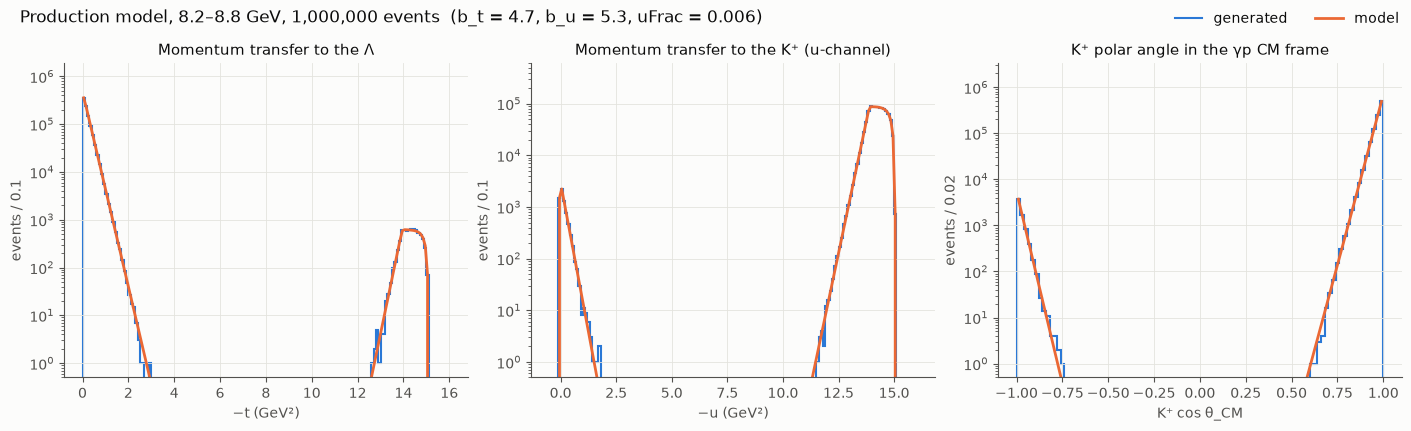

fraction with cos θ_CM < 0: generated 0.00696 ± 0.00008, model 0.00695


In [6]:
n_full = len(full["t"])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), layout="constrained")
specs = [
    ("t", np.linspace(0, 16, 161), "−t (GeV²)"),
    ("u", np.linspace(-0.5, 16, 166), "−u (GeV²)"),
    ("cos_cm", np.linspace(-1, 1, 101), "K⁺ cos θ_CM"),
]
for ax, (var, bins, xlabel) in zip(axes, specs):
    step(ax, full[var], bins)
    model_line(ax, model_hist(var, bins, 0, 20, n_full), bins)
    ax.set_yscale("log")
    ax.set_ylim(bottom=0.5)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"events / {bins[1] - bins[0]:.2g}")
axes[0].set_title("Momentum transfer to the Λ")
axes[1].set_title("Momentum transfer to the K⁺ (u-channel)")
axes[2].set_title("K⁺ polar angle in the γp CM frame")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper right", ncols=2)
fig.suptitle(f"Production model, {E_LOW}–{E_HIGH} GeV, {n_full:,} events  "
             f"(b_t = {T_SLOPE}, b_u = {U_SLOPE}, uFrac = {U_FRAC})", x=0.01, ha="left")
plt.show()

backward = np.mean(full["cos_cm"] < 0)
bins = np.array([-1, 0, 1.0])
model_back = model_hist("cos_cm", bins, 0, 20, 1.0)[0]
print(f"fraction with cos θ_CM < 0: generated {backward:.5f} ± {np.sqrt(backward * (1 - backward) / n_full):.5f}, "
      f"model {model_back:.5f}")

## Polarized sample: beam energy and −t in the analysis window

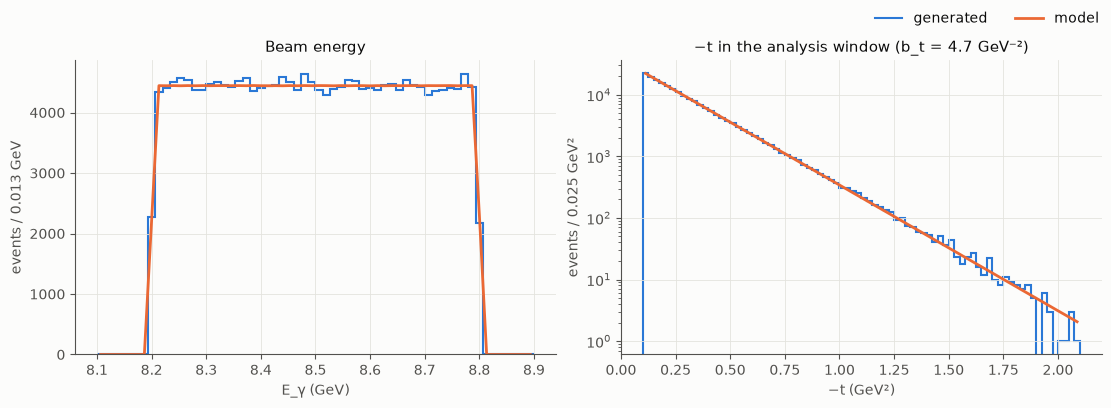

**Events per analysis t bin**

| −t bin (GeV²) | generated events | fraction | model fraction |
| --- | ---: | ---: | ---: |
| 0.1–0.2 | 74,556 | 0.3728 | 0.3751 |
| 0.2–0.3 | 46,985 | 0.2349 | 0.2343 |
| 0.3–0.4 | 29,502 | 0.1475 | 0.1465 |
| 0.4–0.5 | 18,091 | 0.0905 | 0.0916 |
| 0.5–0.6 | 11,559 | 0.0578 | 0.0572 |
| 0.6–0.7 | 7,246 | 0.0362 | 0.0358 |
| 0.7–0.9 | 7,303 | 0.0365 | 0.0363 |
| 0.9–1.3 | 4,049 | 0.0202 | 0.0197 |
| 1.3–2.1 | 709 | 0.0035 | 0.0035 |

In [7]:
n_pol = len(pol["t"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

bins = np.linspace(E_LOW - 0.1, E_HIGH + 0.1, 61)
step(axes[0], pol["E"], bins)
model_line(axes[0], model_hist("E", bins, T_MIN, T_MAX, n_pol), bins)
axes[0].set_xlabel("E_γ (GeV)")
axes[0].set_ylabel(f"events / {bins[1] - bins[0]:.2g} GeV")
axes[0].set_title("Beam energy")

bins = np.linspace(T_MIN, T_MAX, 81)
step(axes[1], pol["t"], bins)
model_line(axes[1], model_hist("t", bins, T_MIN, T_MAX, n_pol), bins)
axes[1].set_yscale("log")
axes[1].set_xlabel("−t (GeV²)")
axes[1].set_ylabel(f"events / {bins[1] - bins[0]:.2g} GeV²")
axes[1].set_title(f"−t in the analysis window (b_t = {T_SLOPE} GeV⁻²)")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper right", ncols=2)
plt.show()

# events per analysis t bin (same binning as runFits.py)
edges = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.9, 1.3, 2.1])
edges = edges[(edges >= T_MIN - 1e-9) & (edges <= T_MAX + 1e-9)]
gen_counts, _ = np.histogram(pol["t"], bins=edges)
expected = model_hist("t", edges, T_MIN, T_MAX, n_pol)
rows = ["| −t bin (GeV²) | generated events | fraction | model fraction |", "| --- | ---: | ---: | ---: |"]
for lo, hi, n, e in zip(edges[:-1], edges[1:], gen_counts, expected):
    rows.append(f"| {lo:.1f}–{hi:.1f} | {n:,} | {n / n_pol:.4f} | {e / n_pol:.4f} |")
display(Markdown("**Events per analysis t bin**\n\n" + "\n".join(rows)))

## Final-state momentum vs polar angle (lab frame)

These plots show where the K⁺, proton and π⁻ go in the detector.  θ_lab is
the polar angle relative to the beam (+z) and p is the lab momentum.  The
color scale is logarithmic.

- **Top row (analysis window):** the polarized sample, in the −t window of the polarization analysis.
- **Bottom row (full angular range):** includes the rare backward (u-channel) events, where the K⁺ goes to large angles with low momentum and the Λ decay products go forward with high momentum.

The axis ranges differ between panels so that each particle's band is
resolved.  The generator writes the same distributions, with fixed ranges, to
each output file as `gen_pTheta_Kp`, `gen_pTheta_p` and `gen_pTheta_pim`.

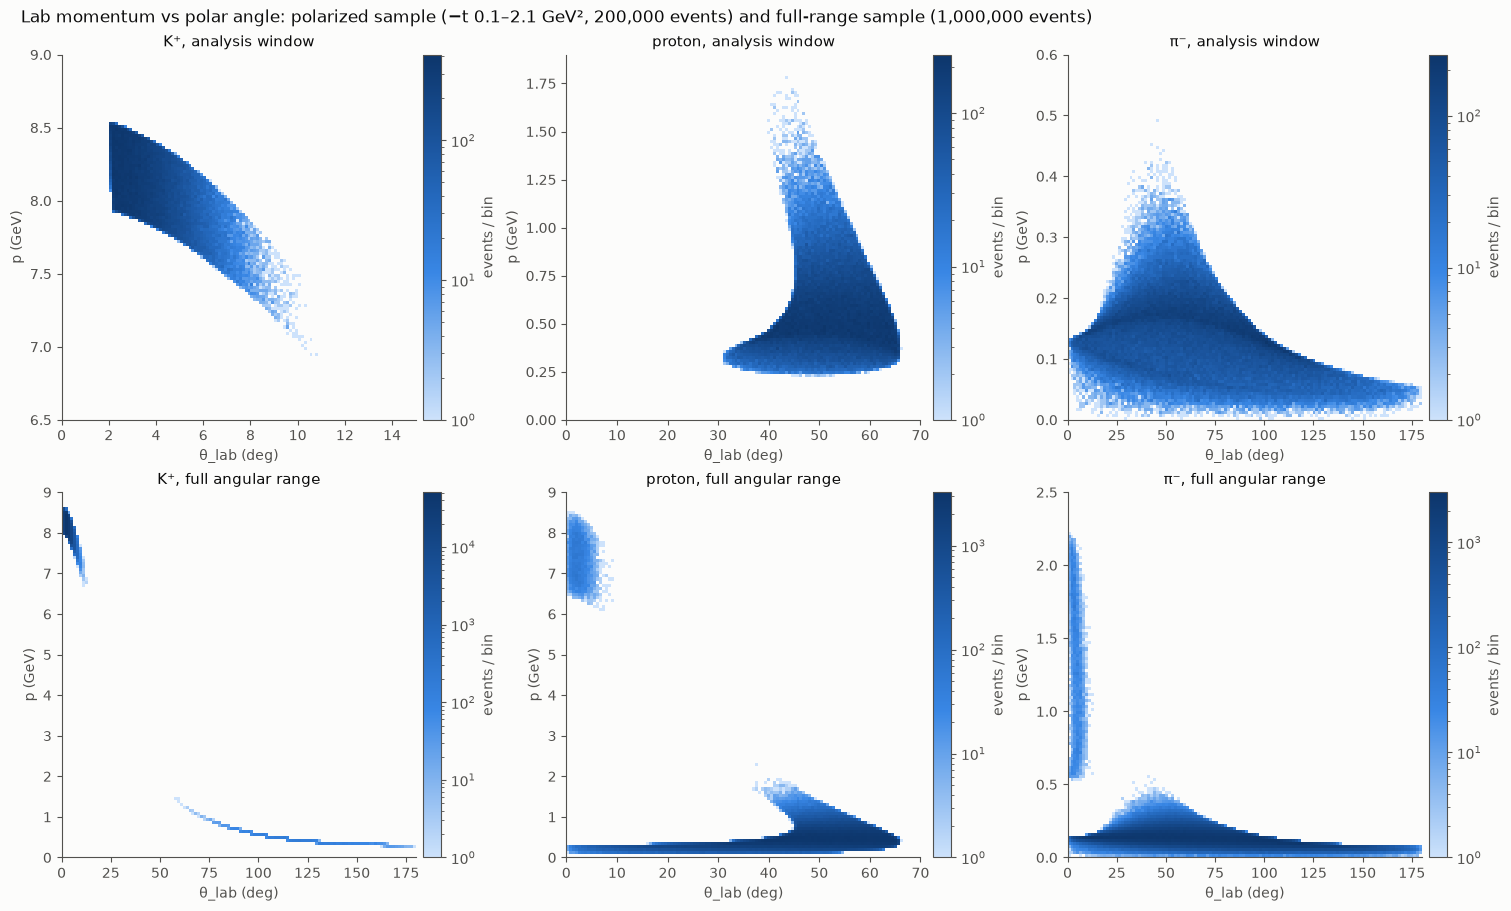

**Final-state momentum and angle ranges**

| Sample | Particle | p (GeV): 0.1% / median / 99.9% | θ_lab (deg): 0.1% / median / 99.9% |
| --- | --- | ---: | ---: |
| analysis window | K⁺ | 7.353 / 8.126 / 8.526 | 2.0 / 3.4 / 8.9 |
| analysis window | proton | 0.245 / 0.516 / 1.393 | 32.5 / 52.8 / 65.7 |
| analysis window | π⁻ | 0.014 / 0.138 / 0.354 | 2.8 / 63.2 / 170.0 |
| full angular range | K⁺ | 0.323 / 8.175 / 8.577 | 0.1 / 2.6 / 148.5 |
| full angular range | proton | 0.097 / 0.418 / 7.913 | 1.1 / 50.1 / 65.6 |
| full angular range | π⁻ | 0.017 / 0.125 / 1.890 | 1.7 / 65.3 / 172.4 |

In [8]:
from matplotlib.colors import LinearSegmentedColormap, LogNorm

# sequential single-hue ramp (light = few events, dark = many); empty bins show the surface
SEQ = LinearSegmentedColormap.from_list(
    "blue_seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
SEQ.set_bad(SURFACE)

PARTICLES = [("K+", "K⁺"), ("p", "proton"), ("pi-", "π⁻")]


def p_theta(ev, name):
    p3 = ev[name][:, 1:]
    p = np.linalg.norm(p3, axis=1)
    return p, np.degrees(np.arccos(np.clip(p3[:, 2] / p, -1, 1)))


def nice_max(x, step):
    return step * np.ceil(np.max(x) * 1.03 / step)


samples = [("analysis window", pol_ev), ("full angular range", full_ev)]
fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout="constrained")
for row, (sample_label, ev) in enumerate(samples):
    for col, (name, label) in enumerate(PARTICLES):
        ax = axes[row, col]
        p, theta = p_theta(ev, name)
        th_max = min(180.0, nice_max(theta, 5.0))
        step = 0.5 if p.max() > 2 else 0.1
        p_max = nice_max(p, step)
        # start the momentum axis just below the data when the band sits far from zero
        p_min = step * np.floor(p.min() * 0.97 / step) if p.min() > 0.25 * p.max() else 0.0
        h, xe, ye = np.histogram2d(theta, p, bins=(120, 120), range=((0, th_max), (p_min, p_max)))
        h = np.ma.masked_equal(h, 0)
        mesh = ax.pcolormesh(xe, ye, h.T, cmap=SEQ, norm=LogNorm(vmin=1, vmax=h.max()),
                             rasterized=True)
        fig.colorbar(mesh, ax=ax, label="events / bin", pad=0.01)
        ax.grid(False)
        ax.set_xlabel("θ_lab (deg)")
        ax.set_ylabel("p (GeV)")
        ax.set_title(f"{label}, {sample_label}")
fig.suptitle(f"Lab momentum vs polar angle: polarized sample (−t {T_MIN}–{T_MAX} GeV², "
             f"{len(pol['t']):,} events) and full-range sample ({len(full['t']):,} events)",
             x=0.01, ha="left")
plt.show()

# momentum and angle ranges, for setting up detector simulation or acceptance studies
rows = ["| Sample | Particle | p (GeV): 0.1% / median / 99.9% | θ_lab (deg): 0.1% / median / 99.9% |",
        "| --- | --- | ---: | ---: |"]
for sample_label, ev in samples:
    for name, label in PARTICLES:
        p, theta = p_theta(ev, name)
        qp = np.percentile(p, [0.1, 50, 99.9])
        qt = np.percentile(theta, [0.1, 50, 99.9])
        rows.append(f"| {sample_label} | {label} | {qp[0]:.3f} / {qp[1]:.3f} / {qp[2]:.3f} "
                    f"| {qt[0]:.1f} / {qt[1]:.1f} / {qt[2]:.1f} |")
display(Markdown("**Final-state momentum and angle ranges**\n\n" + "\n".join(rows)))

## Polarized sample: Λ decay distributions

Each panel compares the generated distribution, normalized to unit area, with
the shape expected from the `KHyperon` intensity:

I ∝ 1 + αP cos θ_y − P_γ cos 2φ (Σ + αT cos θ_y) + P_γ sin 2φ α (Ox cos θ_x + Oz cos θ_z)

Here φ = Φ + (polarization angle).  Integrating over the other variables gives
the following one-dimensional shapes:

- Σ from the Φ distribution: 1 − P_γ Σ cos 2φ.
- P from cos θ_y: 1 + αP cos θ_y.
- Ox and Oz from cos θ_x and cos θ_z, split by the sign of sin 2φ: slope ±(2/π) P_γ α O.
- T from cos θ_y, split by the sign of cos 2φ.

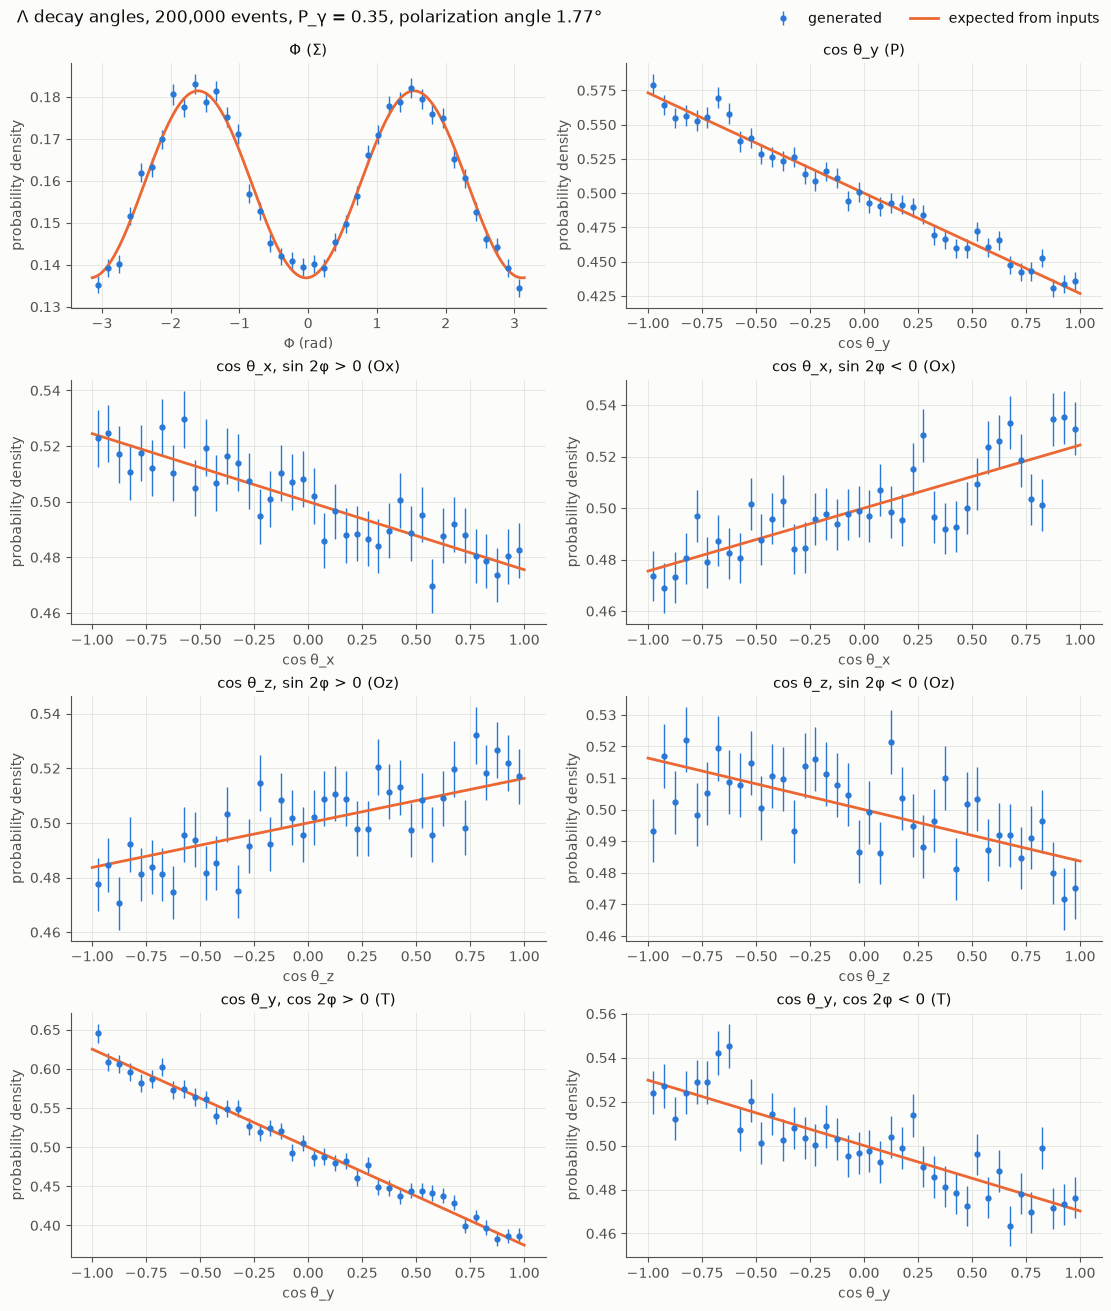

In [9]:
Pg, a = POL_FRACTION, ALPHA
S, Ox, P, T, Oz = (OBSERVABLES[k] for k in ("Sigma", "Ox", "P", "T", "Oz"))
phi = pol["Phi"] + np.radians(POL_ANGLE)
s2, c2 = np.sin(2 * phi), np.cos(2 * phi)
k = 2 / np.pi * Pg * a   # average |sin 2phi| = |cos 2phi| = 2/pi over a half range

panels = [
    ("Φ (Σ)", pol["Phi"], np.ones_like(s2, bool), (-np.pi, np.pi),
     lambda x: (1 - Pg * S * np.cos(2 * (x + np.radians(POL_ANGLE)))) / (2 * np.pi), "Φ (rad)"),
    ("cos θ_y (P)", pol["cy"], np.ones_like(s2, bool), (-1, 1),
     lambda x: (1 + a * P * x) / 2, "cos θ_y"),
    ("cos θ_x, sin 2φ > 0 (Ox)", pol["cx"], s2 > 0, (-1, 1), lambda x: (1 + k * Ox * x) / 2, "cos θ_x"),
    ("cos θ_x, sin 2φ < 0 (Ox)", pol["cx"], s2 < 0, (-1, 1), lambda x: (1 - k * Ox * x) / 2, "cos θ_x"),
    ("cos θ_z, sin 2φ > 0 (Oz)", pol["cz"], s2 > 0, (-1, 1), lambda x: (1 + k * Oz * x) / 2, "cos θ_z"),
    ("cos θ_z, sin 2φ < 0 (Oz)", pol["cz"], s2 < 0, (-1, 1), lambda x: (1 - k * Oz * x) / 2, "cos θ_z"),
    ("cos θ_y, cos 2φ > 0 (T)", pol["cy"], c2 > 0, (-1, 1),
     lambda x: (1 + a * x * (P - 2 / np.pi * Pg * T) / (1 - 2 / np.pi * Pg * S)) / 2, "cos θ_y"),
    ("cos θ_y, cos 2φ < 0 (T)", pol["cy"], c2 < 0, (-1, 1),
     lambda x: (1 + a * x * (P + 2 / np.pi * Pg * T) / (1 + 2 / np.pi * Pg * S)) / 2, "cos θ_y"),
]

fig, axes = plt.subplots(4, 2, figsize=(11, 13), layout="constrained")
for ax, (title, values, sel, rng, model, xlabel) in zip(axes.ravel(), panels):
    bins = np.linspace(*rng, 41)
    centers = 0.5 * (bins[1:] + bins[:-1])
    h, _ = np.histogram(values[sel], bins=bins)
    norm = sel.sum() * (bins[1] - bins[0])
    ax.errorbar(centers, h / norm, yerr=np.sqrt(h) / norm, fmt="o", ms=3.5, color=BLUE,
                elinewidth=1, label="generated")
    x = np.linspace(*rng, 400)
    ax.plot(x, model(x), color=ORANGE, lw=2, label="expected from inputs")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("probability density")
handles, labels = axes[0, 0].get_legend_handles_labels()
order = [labels.index("generated"), labels.index("expected from inputs")]
fig.legend([handles[i] for i in order], [labels[i] for i in order], loc="outside upper right", ncols=2)
fig.suptitle(f"Λ decay angles, {n_pol:,} events, P_γ = {Pg}, polarization angle {POL_ANGLE}°",
             x=0.01, ha="left")
plt.show()

## Observables recovered from the generated events

Each observable can be read off a simple moment of the generated angles, with
no fit and no acceptance:

| Observable | Moment |
| --- | --- |
| Σ | −2⟨cos 2φ⟩ / P_γ |
| P | 3⟨cos θ_y⟩ / α |
| T | −6⟨cos θ_y cos 2φ⟩ / (P_γ α) |
| Ox | 6⟨cos θ_x sin 2φ⟩ / (P_γ α) |
| Oz | 6⟨cos θ_z sin 2φ⟩ / (P_γ α) |

The pull is (recovered − input) / error.  Most pulls should lie within ±2.

In [10]:
def moment(values, scale):
    return scale * values.mean(), abs(scale) * values.std(ddof=1) / np.sqrt(len(values))


estimates = {
    "Sigma": moment(c2, -2 / Pg),
    "P": moment(pol["cy"], 3 / a),
    "T": moment(pol["cy"] * c2, -6 / (Pg * a)),
    "Ox": moment(pol["cx"] * s2, 6 / (Pg * a)),
    "Oz": moment(pol["cz"] * s2, 6 / (Pg * a)),
}
rows = ["| Observable | input | recovered | pull |", "| --- | ---: | ---: | ---: |"]
for name, (value, error) in estimates.items():
    truth = OBSERVABLES[name]
    rows.append(f"| {name} | {truth:+.3f} | {value:+.3f} ± {error:.3f} | {(value - truth) / error:+.1f} |")
display(Markdown("\n".join(rows)))

| Observable | input | recovered | pull |
| --- | ---: | ---: | ---: |
| Sigma | +0.400 | +0.406 ± 0.009 | +0.6 |
| P | -0.200 | -0.197 ± 0.005 | +0.5 |
| T | +0.500 | +0.466 ± 0.021 | -1.6 |
| Ox | -0.300 | -0.296 ± 0.021 | +0.2 |
| Oz | +0.200 | +0.223 ± 0.021 | +1.1 |

## Using the generated files

**Files** (in `gen_khyperon_output/`):

- `polarized.root`: the polarized sample in the −t window.
- `production_full.root`: the unpolarized sample over the full angular range.
- `gen_polarized.cfg`: the generation config written by this notebook.

**Tree** `ntFSGlueX_100000000_100000` has one entry per event, with flat FSRoot-style branches (double precision):

| Particle | Branches |
| --- | --- |
| beam photon | `MCEnPB`, `MCPxPB`, `MCPyPB`, `MCPzPB` |
| K⁺ | `MCEnP2`, `MCPxP2`, `MCPyP2`, `MCPzP2` |
| proton (from Λ) | `MCEnP1a`, `MCPxP1a`, `MCPyP1a`, `MCPzP1a` |
| π⁻ (from Λ) | `MCEnP1b`, `MCPxP1b`, `MCPyP1b`, `MCPzP1b` |
| Λ (= p + π⁻) | `MCEnP1`, `MCPxP1`, `MCPyP1`, `MCPzP1` |

- **Units and frame:** GeV, lab frame.  The beam is along +z and the proton target is at rest.
- **Weights:** all events have weight 1.
- **Diagnostic histograms:** each file also holds `gen_EBeam`, `gen_t`, `gen_u`, `gen_cosThetaCM`, the lab momentum vs polar angle histograms `gen_pTheta_Kp`, `gen_pTheta_p` and `gen_pTheta_pim` (θ in degrees, p in GeV), and the decay-angle histograms.
- **Reading the files:** `FSRootDataReader` in `standalone/` reads them directly as AmpTools `data`, `genmc` or `accmc`.  With PyROOT, `ROOT.RDataFrame("ntFSGlueX_100000000_100000", "polarized.root")` works, as used above.

**Before using these events in a detector simulation:**

- **The events are four-vectors only.** No detector response, resolution or acceptance is applied, and there is no production vertex.  The simulation must assign the target vertex.
- **The Λ decay vertex is not displaced.** The p and π⁻ momenta are correct, but the Λ flight path (cτ ≈ 7.9 cm) is not modeled.  To get realistic tracking, place the p and π⁻ at a decay vertex sampled along the Λ direction from the Λ decay length.  Do not let the simulation decay the Λ itself: that would discard the polarization encoded in the p and π⁻ directions.
- **One polarization orientation and constant P_γ per sample.** To simulate the other orientations, rerun with `POL_ANGLE` set to each one (the fit config uses 1.77, 47.85, 94.50 and −41.57°).  For an energy-dependent polarization, `KHyperon` can read P_γ(E) from a histogram (see `KHyperon.cc`).
- **The observables are constant over t and E within a sample.** To model their t dependence, generate each analysis t bin separately with its own values.
- **The production slopes are a model, not a measurement.** Only b_t matters inside the analysis window.  It can be estimated from data by dividing the yield in each t bin by the phase-space acceptance and fitting an exponential.
- **The Λ has its nominal mass with no width,** so M(pπ⁻) is a delta function.

To make phase-space samples (no polarization) for acceptance studies, add
`-f` and drop `-c`.  Command-line usage is in `standalone/README.md` and
`gen_khyperon -h`.